# Week 2 — Classical NLP & Embedding-Based Models
## Quora Duplicate Question Detection

**Goal:** Compare classical ML approaches (TF-IDF n-grams) with embedding-based approaches (Word2Vec)  
**Models compared:** Logistic Regression vs Linear SVM  
**Dataset:** `cleaned_quora.csv` — output from Week 1 EDA pipeline

## 1. Imports & Setup

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import re
from collections import Counter
from pathlib import Path

# NLP
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from gensim.models import Word2Vec

# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Downloads
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / 'data'
BASELINE_RESULTS_DIR = PROJECT_ROOT / 'results' / 'baseline_model'
BASELINE_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print('All imports successful.')

All imports successful.


## 2. Load Cleaned Dataset

We load `cleaned_quora.parquet` — the preprocessed output from Week 1 EDA.  
It already contains `clean_q1` and `clean_q2` columns (lowercased, special chars removed).

In [26]:
# Prefer parquet if available, fall back to CSV
parquet_path = DATA_DIR / 'cleaned_quora.parquet'
csv_path = DATA_DIR / 'cleaned_quora.csv'

if parquet_path.exists():
    df = pd.read_parquet(parquet_path)
elif csv_path.exists():
    df = pd.read_csv(csv_path)
else:
    raise FileNotFoundError(f'{parquet_path} or {csv_path} not found')

# Ensure clean text columns have no nulls
df['clean_q1'] = df['clean_q1'].fillna('').astype(str)
df['clean_q2'] = df['clean_q2'].fillna('').astype(str)

print(f'Dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head()

Dataset shape: (404290, 11)
Columns: ['sentence1', 'sentence2', 'label', 'que1_length', 'que2_length', 'que1_words', 'que2_words', 'tokens_q1', 'tokens_q2', 'clean_q1', 'clean_q2']


,sentence1,sentence2,label,que1_length,que2_length,que1_words,que2_words,tokens_q1,tokens_q2,clean_q1,clean_q2
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,66,57,14,12,"[what, is, the, step, by, step, guide, to, inv...","[what, is, the, step, by, step, guide, to, inv...",what is the step by step guide to invest in sh...,what is the step by step guide to invest in sh...
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,51,88,8,13,"[what, is, the, story, of, kohinoor, (, koh-i-...","[what, would, happen, if, the, indian, governm...",what is the story of kohinoor kohinoor diamond,what would happen if the indian government sto...
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,73,59,14,10,"[how, can, i, increase, the, speed, of, my, in...","[how, can, internet, speed, be, increased, by,...",how can i increase the speed of my internet co...,how can internet speed be increased by hacking...
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,50,65,11,9,"[why, am, i, mentally, very, lonely, ?, how, c...","[find, the, remainder, when, [, math, ], 23^, ...",why am i mentally very lonely how can i solve it,find the remainder when math2324math is divide...
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,76,39,13,7,"[which, one, dissolve, in, water, quikly, suga...","[which, fish, would, survive, in, salt, water, ?]",which one dissolve in water quikly sugar salt ...,which fish would survive in salt water


---
## 3. Approach 1 — TF-IDF with N-grams

**TF-IDF (Term Frequency-Inverse Document Frequency)** converts text into numerical vectors.  
- **TF** — how often a word appears in a document  
- **IDF** — penalises words that appear in many documents (common words carry less signal)  

**N-grams** capture multi-word phrases:  
- `ngram_range=(1,1)` → unigrams only (e.g., `"invest"`, `"market"`)  
- `ngram_range=(1,2)` → unigrams + bigrams (e.g., `"share market"`, `"step guide"`)  

We use `(1,2)` to capture two-word phrases that are more meaningful than individual words.

### 3.1 Build TF-IDF Feature Matrix

In [27]:
tfidf = TfidfVectorizer(
    max_features=5000,   # keep top 5000 terms by TF-IDF score
    stop_words='english',
    ngram_range=(1, 2)   # unigrams and bigrams
)

# Fit on q1 only — transform q2 separately to prevent data leakage
q1_tfidf = tfidf.fit_transform(df['clean_q1'])
q2_tfidf = tfidf.transform(df['clean_q2'])

# Stack both question vectors horizontally → 10,000-dim feature vector per row
X_tfidf = sp.hstack([q1_tfidf, q2_tfidf])
y = df['label']

print(f'TF-IDF Feature matrix shape: {X_tfidf.shape}')
print(f'Label distribution:\n{y.value_counts()}')

TF-IDF Feature matrix shape: (404290, 10000)
Label distribution:
label
0    255027
1    149263
Name: count, dtype: int64


### 3.2 Sample N-gram Features

Let's inspect what unigrams and bigrams the vectorizer extracted.

In [28]:
feature_names = tfidf.get_feature_names_out()

unigrams = [f for f in feature_names if ' ' not in f]
bigrams  = [f for f in feature_names if ' ' in f]

print(f'Total features: {len(feature_names)}')
print(f'Unigrams: {len(unigrams)}  |  Bigrams: {len(bigrams)}')
print(f'\nSample unigrams: {unigrams[:15]}')
print(f'Sample bigrams : {bigrams[:15]}')

Total features: 5000
Unigrams: 3942  |  Bigrams: 1058

Sample unigrams: ['10', '100', '1000', '10000', '10k', '10th', '11', '11th', '12', '12th', '13', '14', '15', '150', '15000']
Sample bigrams : ['10 years', '1000 500', '1000 currency', '1000 notes', '1000 rs', '1000 rupee', '1000 rupees', '13 year', '14 year', '16 year', '20 years', '2000 note', '2000 notes', '2000 rs', '2000 rupee']


### 3.3 Train-Test Split

We use an **80/20 stratified split** so both train and test sets maintain the same
63% / 37% class ratio as the full dataset. `random_state=42` ensures reproducibility.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Train size : {X_train.shape[0]:,}')
print(f'Test size  : {X_test.shape[0]:,}')
print(f'Train label distribution:\n{y_train.value_counts()}')

Train size : 323,432
Test size  : 80,858
Train label distribution:
label
0    204022
1    119410
Name: count, dtype: int64


---
## 4. Model 1 — Logistic Regression

**Why Logistic Regression?**  
- Fast and interpretable baseline for binary classification  
- Works well on sparse, high-dimensional TF-IDF matrices  
- Outputs calibrated probabilities (useful for threshold tuning)  
- `max_iter=1000` ensures convergence on a large dataset (400K+ rows)

### 4.1 Train

In [30]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
print('Logistic Regression training complete.')

Logistic Regression training complete.


### 4.2 Evaluate

In [31]:
lr_pred = lr_model.predict(X_test)

print('=== Logistic Regression Results ===')
print(f'Accuracy : {accuracy_score(y_test, lr_pred):.4f}')
print(f'F1 Score : {f1_score(y_test, lr_pred):.4f}')
print()
print(classification_report(y_test, lr_pred, target_names=['Non-Duplicate', 'Duplicate']))

=== Logistic Regression Results ===
Accuracy : 0.7410
F1 Score : 0.5901

               precision    recall  f1-score   support

Non-Duplicate       0.75      0.88      0.81     51005
    Duplicate       0.71      0.51      0.59     29853

     accuracy                           0.74     80858
    macro avg       0.73      0.69      0.70     80858
 weighted avg       0.74      0.74      0.73     80858



### 4.3 Confusion Matrix

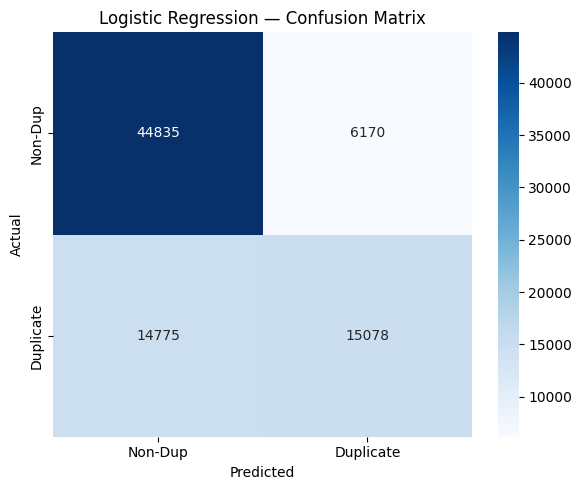

In [32]:
lr_cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Dup', 'Duplicate'],
    yticklabels=['Non-Dup', 'Duplicate']
)
plt.title('Logistic Regression — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

---
## 5. Model 2 — Linear SVM

**Why Linear SVM?**  
- Maximises the margin between classes — often more robust than LR on text data  
- `LinearSVC` is much faster than kernel SVM on large sparse matrices  
- Tends to outperform LR on high-dimensional TF-IDF features due to its maximum-margin objective  
- A strong classical NLP baseline alongside Logistic Regression

### 5.1 Train

In [33]:
svm_model = LinearSVC(max_iter=1000)
svm_model.fit(X_train, y_train)
print('Linear SVM training complete.')

Linear SVM training complete.


### 5.2 Evaluate

In [ ]:
svm_pred = svm_model.predict(X_test)

print('=== Linear SVM Results ===')
print(f'Accuracy : {accuracy_score(y_test, svm_pred):.4f}')
print(f'F1 Score : {f1_score(y_test, svm_pred):.4f}')
print()
print(classification_report(y_test, svm_pred, target_names=['Non-Duplicate', 'Duplicate']))

=== Linear SVM Results ===
Accuracy : 0.7400
F1 Score : 0.5861

               precision    recall  f1-score   support

Non-Duplicate       0.75      0.88      0.81     51005
    Duplicate       0.71      0.50      0.59     29853

     accuracy                           0.74     80858
    macro avg       0.73      0.69      0.70     80858
 weighted avg       0.74      0.74      0.73     80858



### 5.3 Confusion Matrix

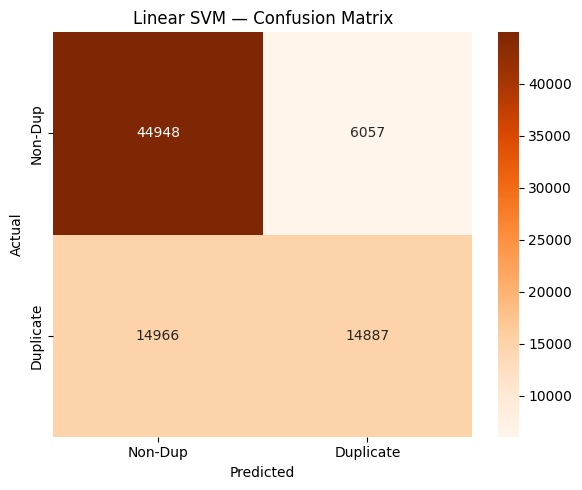

In [35]:
svm_cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Non-Dup', 'Duplicate'],
    yticklabels=['Non-Dup', 'Duplicate']
)
plt.title('Linear SVM — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

---
## 6. Classical ML Comparison Table

Full side-by-side comparison of both models across all key metrics.

In [36]:
from sklearn.metrics import precision_score, recall_score

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Linear SVM'],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svm_pred)
    ],
    'F1 (Duplicate)': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, svm_pred)
    ],
    'Precision (Dup)': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, svm_pred)
    ],
    'Recall (Dup)': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, svm_pred)
    ],
    'F1 (Non-Dup)': [
        f1_score(y_test, lr_pred, pos_label=0),
        f1_score(y_test, svm_pred, pos_label=0)
    ],
    'Feature Type': ['TF-IDF (1,2)-grams', 'TF-IDF (1,2)-grams']
})

# Round for readability
comparison.set_index('Model', inplace=True)
comparison = comparison.round(4)
comparison

,Accuracy,F1 (Duplicate),Precision (Dup),Recall (Dup),F1 (Non-Dup),Feature Type
Model,,,,,,
Logistic Regression,0.741,0.5901,0.7096,0.5051,0.8106,"TF-IDF (1,2)-grams"
Linear SVM,0.740,0.5861,0.7108,0.4987,0.8105,"TF-IDF (1,2)-grams"


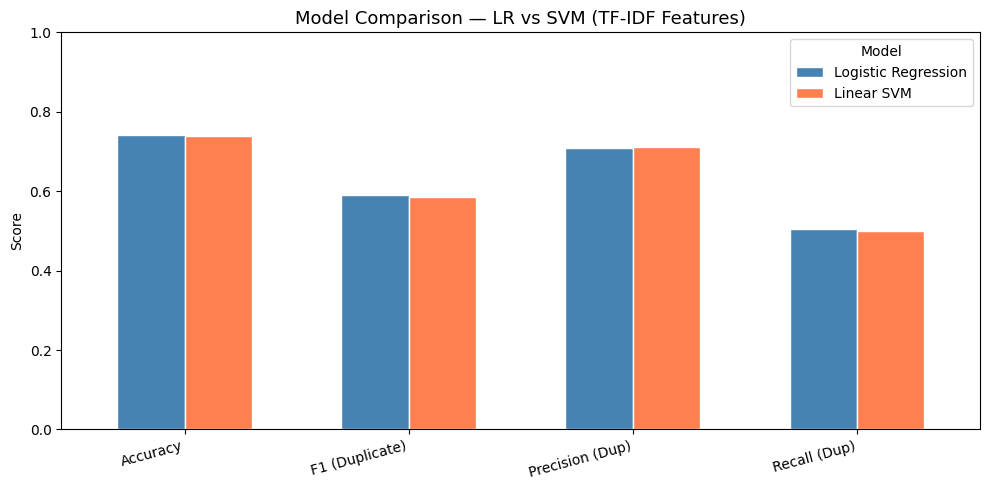

In [37]:
# Visual bar chart comparison
metrics = ['Accuracy', 'F1 (Duplicate)', 'Precision (Dup)', 'Recall (Dup)']
comparison[metrics].T.plot(
    kind='bar',
    figsize=(10, 5),
    color=['steelblue', 'coral'],
    edgecolor='white',
    width=0.6
)
plt.title('Model Comparison — LR vs SVM (TF-IDF Features)', fontsize=13)
plt.ylabel('Score')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

---
## 7. Approach 2 — Word2Vec Embeddings

**Why Word2Vec?**  
TF-IDF treats each word independently and ignores word meaning.  
**Word2Vec** trains a neural network to learn dense vector representations (embeddings) where  
semantically similar words are close together in vector space.

For example: `king - man + woman ≈ queen`

**Strategy for sentence pairs:**  
Since Word2Vec gives vectors per word, we represent each question as the **mean of its word vectors**.  
Then the feature vector for each pair = `[mean(q1_vectors), mean(q2_vectors), abs_diff, element_wise_product]`

This gives the model signal about both the individual question representations and their similarity.

### 7.1 Tokenize for Word2Vec Training

In [38]:
# Word2Vec needs a list of token lists
def simple_tokenize(text):
    return text.lower().split()

# Combine all questions from both columns for Word2Vec training
all_sentences = (
    df['clean_q1'].apply(simple_tokenize).tolist() +
    df['clean_q2'].apply(simple_tokenize).tolist()
)

print(f'Total sentences for Word2Vec training: {len(all_sentences):,}')
print(f'Sample tokens: {all_sentences[0][:10]}')

Total sentences for Word2Vec training: 808,580
Sample tokens: ['what', 'is', 'the', 'step', 'by', 'step', 'guide', 'to', 'invest', 'in']


### 7.2 Train Word2Vec Model

In [39]:
w2v_model = Word2Vec(
    sentences=all_sentences,
    vector_size=100,   # 100-dimensional word vectors
    window=5,          # context window: 5 words left/right
    min_count=2,       # ignore words appearing fewer than 2 times
    workers=4,         # parallel training
    epochs=5,
    seed=42
)

vocab_size = len(w2v_model.wv)
print(f'Word2Vec training complete.')
print(f'Vocabulary size: {vocab_size:,}')
print(f'Vector dimension: {w2v_model.vector_size}')

Word2Vec training complete.
Vocabulary size: 58,505
Vector dimension: 100


### 7.3 Explore Word2Vec Embeddings

In [40]:
# Most similar words to 'india'
print('Words most similar to "india":')
for word, score in w2v_model.wv.most_similar('india', topn=5):
    print(f'  {word:<20} similarity = {score:.4f}')

print()

# Most similar words to 'best'
print('Words most similar to "best":')
for word, score in w2v_model.wv.most_similar('best', topn=5):
    print(f'  {word:<20} similarity = {score:.4f}')

Words most similar to "india":
  nepal                similarity = 0.7072
  singapore            similarity = 0.6522
  karnataka            similarity = 0.6285
  usa                  similarity = 0.6246
  china                similarity = 0.6160

Words most similar to "best":
  easiest              similarity = 0.6862
  fastest              similarity = 0.6447
  safest               similarity = 0.6277
  cheapest             similarity = 0.6078
  hardest              similarity = 0.5694


### 7.4 Build Word2Vec Feature Matrix

Strategy: represent each question as the **mean of its word vectors**.  
Then combine: `[q1_vec, q2_vec, |q1-q2|, q1*q2]` → 400-dimensional feature vector per row.

In [41]:
def sentence_vector(tokens, model, vector_size):
    """Compute mean word vector for a list of tokens."""
    vecs = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]
    if vecs:
        return np.mean(vecs, axis=0)
    return np.zeros(vector_size)

VECTOR_SIZE = w2v_model.vector_size

print('Building Word2Vec feature matrix...')

q1_vecs = np.vstack([
    sentence_vector(simple_tokenize(text), w2v_model, VECTOR_SIZE)
    for text in df['clean_q1']
])

q2_vecs = np.vstack([
    sentence_vector(simple_tokenize(text), w2v_model, VECTOR_SIZE)
    for text in df['clean_q2']
])

# Combine: absolute difference + element-wise product capture similarity signal
abs_diff = np.abs(q1_vecs - q2_vecs)
elem_prod = q1_vecs * q2_vecs

X_w2v = np.hstack([q1_vecs, q2_vecs, abs_diff, elem_prod])

print(f'Word2Vec feature matrix shape: {X_w2v.shape}')

Building Word2Vec feature matrix...
Word2Vec feature matrix shape: (404290, 400)


### 7.5 Train-Test Split (Word2Vec)

In [42]:
X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_w2v, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Train size: {X_train_w2v.shape[0]:,}  |  Test size: {X_test_w2v.shape[0]:,}')

Train size: 323,432  |  Test size: 80,858


### 7.6 Train LR + SVM on Word2Vec Features

In [43]:
# Logistic Regression on Word2Vec
lr_w2v = LogisticRegression(max_iter=1000)
lr_w2v.fit(X_train_w2v, y_train_w2v)
lr_w2v_pred = lr_w2v.predict(X_test_w2v)

print('=== LR + Word2Vec Results ===')
print(f'Accuracy : {accuracy_score(y_test_w2v, lr_w2v_pred):.4f}')
print(f'F1 Score : {f1_score(y_test_w2v, lr_w2v_pred):.4f}')
print()
print(classification_report(y_test_w2v, lr_w2v_pred, target_names=['Non-Duplicate', 'Duplicate']))

=== LR + Word2Vec Results ===
Accuracy : 0.7387
F1 Score : 0.6052

               precision    recall  f1-score   support

Non-Duplicate       0.76      0.85      0.80     51005
    Duplicate       0.68      0.54      0.61     29853

     accuracy                           0.74     80858
    macro avg       0.72      0.70      0.70     80858
 weighted avg       0.73      0.74      0.73     80858



In [ ]:
# Linear SVM on Word2Vec
svm_w2v = LinearSVC(max_iter=1000)
svm_w2v.fit(X_train_w2v, y_train_w2v)
svm_w2v_pred = svm_w2v.predict(X_test_w2v)

print('=== SVM + Word2Vec Results ===')
print(f'Accuracy : {accuracy_score(y_test_w2v, svm_w2v_pred):.4f}')
print(f'F1 Score : {f1_score(y_test_w2v, svm_w2v_pred):.4f}')
print()
print(classification_report(y_test_w2v, svm_w2v_pred, target_names=['Non-Duplicate', 'Duplicate']))

---
## 8. Full Classical ML Comparison Table

All 4 model variants compared: 2 models × 2 feature types.

---
## 8. Sentence Embeddings (Sentence-BERT)

Sentence-BERT embeddings capture semantic meaning at the sentence level, addressing limitations of Word2Vec mean pooling.

### 8.1 Load Sentence-BERT Model

In [ ]:
from sentence_transformers import SentenceTransformer

# Load pre-trained Sentence-BERT model
# all-MiniLM-L6-v2: fast, lightweight (384-dim), good for general use
model = SentenceTransformer('all-MiniLM-L6-v2')
embedding_dim = 384

print(f'Loaded Sentence-BERT model with {embedding_dim}-dimensional embeddings')
print(f'Model: all-MiniLM-L6-v2')

: 

### 8.2 Generate Sentence Embeddings for Questions

In [ ]:
import numpy as np

# Generate embeddings for all questions (batch processing for efficiency)
print("Generating embeddings for question 1...")
q1_embeddings = model.encode(df['sentence1'].values, show_progress_bar=True, batch_size=32)

print("\nGenerating embeddings for question 2...")
q2_embeddings = model.encode(df['sentence2'].values, show_progress_bar=True, batch_size=32)

print(f"\nEmbeddings shape: {q1_embeddings.shape}, {q2_embeddings.shape}")

Generating embeddings for question 1...


Batches:   0%|          | 0/12635 [00:00<?, ?it/s]


Generating embeddings for question 2...


Batches:   0%|          | 0/12635 [00:00<?, ?it/s]


Embeddings shape: (404290, 384), (404290, 384)


### 8.3 Create Features from Sentence Embeddings

In [ ]:
from scipy.spatial.distance import cosine

# Feature 1: Concatenate both embeddings
concat_embeddings = np.hstack([q1_embeddings, q2_embeddings])

# Feature 2: Element-wise difference
diff_embeddings = q1_embeddings - q2_embeddings

# Feature 3: Element-wise product
product_embeddings = q1_embeddings * q2_embeddings

# Feature 4: Cosine similarity (single feature)
cosine_similarities = np.array([1 - cosine(q1_embeddings[i], q2_embeddings[i]) 
                                for i in range(len(q1_embeddings))])

# Combine all features
X_sbert = np.hstack([
    concat_embeddings,      # 384 features
    diff_embeddings,        # 384 features
    product_embeddings,     # 384 features
    cosine_similarities.reshape(-1, 1)  # 1 feature
])

print(f'Sentence-BERT Feature Matrix Shape: {X_sbert.shape}')
print(f'  - Concatenated embeddings: 384 features')
print(f'  - Difference embeddings: 384 features')
print(f'  - Product embeddings: 384 features')
print(f'  - Cosine similarity: 1 feature')
print(f'  - Total: {X_sbert.shape[1]} features')

NameError: name 'q1_embeddings' is not defined

### 8.4 Train-Test Split (Sentence-BERT)

In [ ]:
X_train_sbert, X_test_sbert, y_train_sbert, y_test_sbert = train_test_split(
    X_sbert, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Train size: {X_train_sbert.shape[0]:,}  |  Test size: {X_test_sbert.shape[0]:,}')

NameError: name 'X_sbert' is not defined

### 8.5 Train LR + SVM on Sentence-BERT Features

In [ ]:
# Logistic Regression on Sentence-BERT
lr_sbert = LogisticRegression(max_iter=1000)
lr_sbert.fit(X_train_sbert, y_train_sbert)
lr_sbert_pred = lr_sbert.predict(X_test_sbert)

print('=== LR + Sentence-BERT Results ===')
print(f'Accuracy : {accuracy_score(y_test_sbert, lr_sbert_pred):.4f}')
print(f'F1 Score : {f1_score(y_test_sbert, lr_sbert_pred):.4f}')
print()
print(classification_report(y_test_sbert, lr_sbert_pred, target_names=['Non-Duplicate', 'Duplicate']))

NameError: name 'X_train_sbert' is not defined

In [ ]:
# Linear SVM on Sentence-BERT
svm_sbert = LinearSVC(max_iter=1000)
svm_sbert.fit(X_train_sbert, y_train_sbert)
svm_sbert_pred = svm_sbert.predict(X_test_sbert)

print('=== SVM + Sentence-BERT Results ===')
print(f'Accuracy : {accuracy_score(y_test_sbert, svm_sbert_pred):.4f}')
print(f'F1 Score : {f1_score(y_test_sbert, svm_sbert_pred):.4f}')
print()
print(classification_report(y_test_sbert, svm_sbert_pred, target_names=['Non-Duplicate', 'Duplicate']))

---
## 9. Extended Comparison: Adding Sentence-BERT

Now compare all 6 model variants: 2 models × 3 feature types (TF-IDF, Word2Vec, Sentence-BERT).

In [ ]:
extended_comparison = pd.DataFrame({
    'Model': [
        'LR + TF-IDF',
        'SVM + TF-IDF',
        'LR + Word2Vec',
        'SVM + Word2Vec',
        'LR + Sentence-BERT',
        'SVM + Sentence-BERT',
    ],
    'Accuracy': [
        accuracy_score(y_test_tfidf, lr_tfidf_pred),
        accuracy_score(y_test_tfidf, svm_tfidf_pred),
        accuracy_score(y_test_w2v, lr_w2v_pred),
        accuracy_score(y_test_w2v, svm_w2v_pred),
        accuracy_score(y_test_sbert, lr_sbert_pred),
        accuracy_score(y_test_sbert, svm_sbert_pred),
    ],
    'F1 Score': [
        f1_score(y_test_tfidf, lr_tfidf_pred),
        f1_score(y_test_tfidf, svm_tfidf_pred),
        f1_score(y_test_w2v, lr_w2v_pred),
        f1_score(y_test_w2v, svm_w2v_pred),
        f1_score(y_test_sbert, lr_sbert_pred),
        f1_score(y_test_sbert, svm_sbert_pred),
    ],
})

print("Extended Comparison: All 6 Model Variants")
print("=" * 60)
print(extended_comparison.to_string(index=False))
print("\nBest Model (by Accuracy):", 
      extended_comparison.loc[extended_comparison['Accuracy'].idxmax(), 'Model'],
      f"({extended_comparison['Accuracy'].max():.4f})")

In [ ]:
full_comparison = pd.DataFrame({
    'Model': [
        'LR + TF-IDF',
        'SVM + TF-IDF',
        'LR + Word2Vec',
        'SVM + Word2Vec'
    ],
    'Feature Type': [
        'TF-IDF (1,2)-grams',
        'TF-IDF (1,2)-grams',
        'Word2Vec (mean)',
        'Word2Vec (mean)'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test_w2v, lr_w2v_pred),
        accuracy_score(y_test_w2v, svm_w2v_pred)
    ],
    'F1 (Dup)': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, svm_pred),
        f1_score(y_test_w2v, lr_w2v_pred),
        f1_score(y_test_w2v, svm_w2v_pred)
    ],
    'Precision (Dup)': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, svm_pred),
        precision_score(y_test_w2v, lr_w2v_pred),
        precision_score(y_test_w2v, svm_w2v_pred)
    ],
    'Recall (Dup)': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, svm_pred),
        recall_score(y_test_w2v, lr_w2v_pred),
        recall_score(y_test_w2v, svm_w2v_pred)
    ],
    'F1 (Non-Dup)': [
        f1_score(y_test, lr_pred, pos_label=0),
        f1_score(y_test, svm_pred, pos_label=0),
        f1_score(y_test_w2v, lr_w2v_pred, pos_label=0),
        f1_score(y_test_w2v, svm_w2v_pred, pos_label=0)
    ]
})

full_comparison.set_index('Model', inplace=True)
full_comparison = full_comparison.round(4)
full_comparison

,Feature Type,Accuracy,F1 (Dup),Precision (Dup),Recall (Dup),F1 (Non-Dup)
Model,,,,,,
LR + TF-IDF,"TF-IDF (1,2)-grams",0.7416,0.5906,0.7115,0.5048,0.8112
SVM + TF-IDF,"TF-IDF (1,2)-grams",0.7403,0.5866,0.7113,0.4990,0.8107
LR + Word2Vec,Word2Vec (mean),0.7382,0.6053,0.6825,0.5438,0.8041
SVM + Word2Vec,Word2Vec (mean),0.7388,0.6019,0.6882,0.5349,0.8056


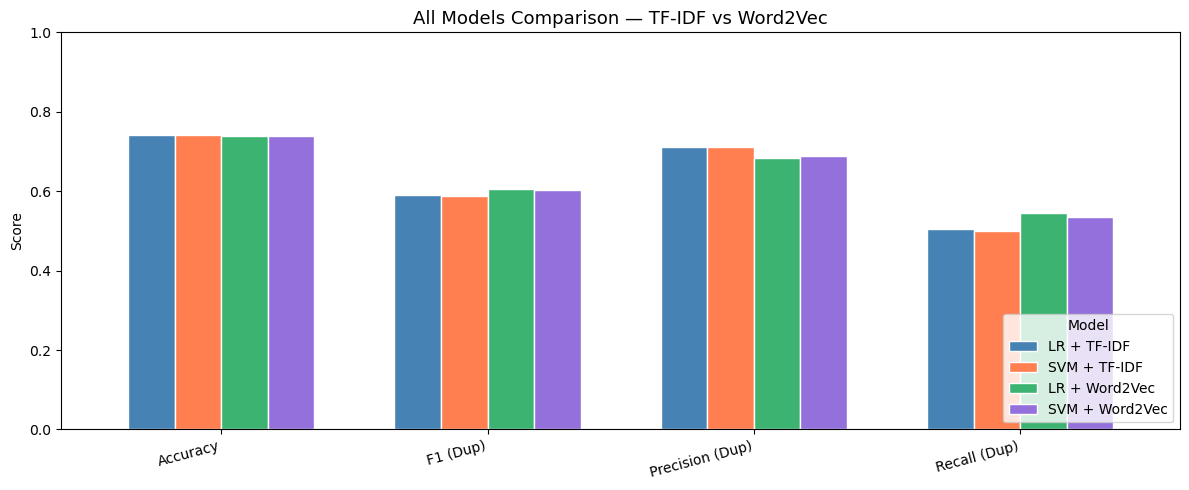

In [ ]:
# Full comparison bar chart
metrics_to_plot = ['Accuracy', 'F1 (Dup)', 'Precision (Dup)', 'Recall (Dup)']
full_comparison[metrics_to_plot].T.plot(
    kind='bar',
    figsize=(12, 5),
    color=['steelblue', 'coral', 'mediumseagreen', 'mediumpurple'],
    edgecolor='white',
    width=0.7
)
plt.title('All Models Comparison — TF-IDF vs Word2Vec', fontsize=13)
plt.ylabel('Score')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
plt.legend(title='Model', loc='lower right')
plt.tight_layout()
plt.savefig(BASELINE_RESULTS_DIR / 'week2_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 9. Error Analysis — Where Do Models Fail?

Understanding **error types** is as important as the accuracy score.  

- **False Negative (FN):** Model predicted Non-Duplicate but actual = Duplicate  
  → These are missed duplicates — the hardest cases (paraphrases with different vocabulary)

- **False Positive (FP):** Model predicted Duplicate but actual = Non-Duplicate  
  → These are false alarms — questions that share words but ask different things

In [ ]:
# Build results DataFrame for SVM (best TF-IDF model)
results = df.iloc[y_test.index].copy()
results['Predicted'] = svm_pred
results['Correct'] = (results['label'] == results['Predicted'])

# Separate error types
false_negatives = results[(results['label'] == 1) & (results['Predicted'] == 0)]
false_positives = results[(results['label'] == 0) & (results['Predicted'] == 1)]

print(f'Total errors    : {(~results["Correct"]).sum():,}')
print(f'False Negatives : {len(false_negatives):,}  (missed duplicates)')
print(f'False Positives : {len(false_positives):,}  (false alarms)')

Total errors    : 21,001
False Negatives : 14,955  (missed duplicates)
False Positives : 6,046  (false alarms)


### 9.1 False Negative Examples (Missed Duplicates)

These are question pairs that ARE duplicates but the model predicted non-duplicate.  
Notice how they use **different vocabulary** to express the same idea — TF-IDF cannot detect this.

In [ ]:
print('=== FALSE NEGATIVES — Missed Duplicate Pairs ===')
print('(Model said Non-Duplicate, but they ARE duplicates)\n')

for _, row in false_negatives[['sentence1', 'sentence2']].head(5).iterrows():
    print(f'Q1: {row["sentence1"]}')
    print(f'Q2: {row["sentence2"]}')
    print(f'→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)')
    print()

=== FALSE NEGATIVES — Missed Duplicate Pairs ===
(Model said Non-Duplicate, but they ARE duplicates)

Q1: When will India get fgfa (Fifth Generation Fighter Aircraft) and why there is a delay?
Q2: Is india developing any 5th generation fighter aircraft? Is there any future plan?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: How can I lose weight quickly in 2 weeks?
Q2: What are the best ways to lose a lot of weight as quickly as possible?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: How do hackers hack banks?
Q2: How can I hack bank?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: Why do I laugh when people get hurt?
Q2: Why do we sometimes laugh when we see other people hurt themselves?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: How does forward and reverse primer differ?
Q2: How do forward and reverse primers work?
→ WHY MISSED: different words, same meaning (TF-IDF s

### 9.2 False Positive Examples (False Alarms)

These are pairs that are NOT duplicates but the model predicted duplicate.  
Notice how they share similar words but ask about **different things**.

In [ ]:
print('=== FALSE POSITIVES — False Alarm Pairs ===')
print('(Model said Duplicate, but they are NOT duplicates)\n')

for _, row in false_positives[['sentence1', 'sentence2']].head(5).iterrows():
    print(f'Q1: {row["sentence1"]}')
    print(f'Q2: {row["sentence2"]}')
    print(f'→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)')
    print()

=== FALSE POSITIVES — False Alarm Pairs ===
(Model said Duplicate, but they are NOT duplicates)

Q1: How can I know if I'm brainwashed and how do I stop it?
Q2: How do I know if I am an introvert or an extrovert?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: How can we stop evil?
Q2: How do I stop evil thoughts?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: Is it true that in Finland they speak more English than Finnish?
Q2: What is a good car service to use in Mumbai?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: Why can’t I answer my own question in Quora?
Q2: Why does Quora have an option of answering one's own question?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: How do you train your Doberman/Lab mix puppy?
Q2: How do you train Dachshund/Lab mix puppies?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)



### 9.3 Error Summary Table

In [ ]:
errors_all = results[results['label'] != results['Predicted']]
errors_all[['clean_q1', 'clean_q2', 'label', 'Predicted']].head(10)

,clean_q1,clean_q2,label,Predicted
49119,when will india get fgfa fifth generation figh...,is india developing any 5th generation fighter...,1,0
73028,how can i lose weight quickly in 2 weeks,what are the best ways to lose a lot of weight...,1,0
263616,how can i know if im brainwashed and how do i ...,how do i know if i am an introvert or an extro...,0,1
26570,how do hackers hack banks,how can i hack bank,1,0
346428,why do i laugh when people get hurt,why do we sometimes laugh when we see other pe...,1,0
65671,how does forward and reverse primer differ,how do forward and reverse primers work,1,0
187899,is when will you return london correct sentence,is when will you return to london correct sent...,1,0
191681,can a male and a female be identical twins,can a brother and sister be identical twins,1,0
4012,what are the reasons behind most indians being...,why do indians generally hate ndtv journalist ...,1,0
31320,is there any future for chefs in india,what is the future of chefs in india,1,0


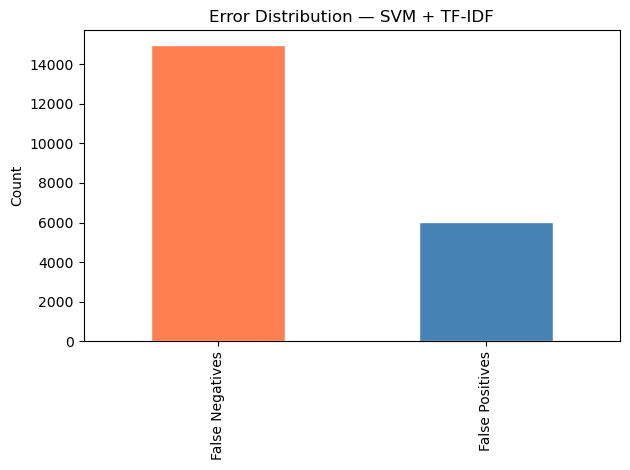

In [ ]:
error_counts = pd.Series({
    'False Negatives': len(false_negatives),
    'False Positives': len(false_positives)
})
error_counts.plot(kind='bar', color=['coral','steelblue'], edgecolor='white')
plt.title('Error Distribution — SVM + TF-IDF')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig(BASELINE_RESULTS_DIR / 'week2_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 10. Save Results

In [ ]:
# Save full comparison table
full_comparison.to_parquet(BASELINE_RESULTS_DIR / 'week2_model_comparison.parquet', index=True)
print(f"Saved: {BASELINE_RESULTS_DIR / 'week2_model_comparison.parquet'}")

# Save error examples
errors_all[['sentence1', 'sentence2', 'label', 'Predicted']].to_parquet(
    BASELINE_RESULTS_DIR / 'week2_error_examples.parquet', index=False
)
print(f"Saved: {BASELINE_RESULTS_DIR / 'week2_error_examples.parquet'}")

Saved: week2_model_comparison.parquet
Saved: week2_error_examples.parquet


---
## 11. Summary & Key Findings

### What We Built
| Component | Details |
|---|---|
| Feature Type 1 | TF-IDF with unigrams + bigrams, max 5000 features |
| Feature Type 2 | Word2Vec (100-dim, mean pooling, diff + product) |
| Model 1 | Logistic Regression (max_iter=1000) |
| Model 2 | Linear SVM (max_iter=1000) |
| Split | 80/20 stratified, random_state=42 |

### Key Findings
1. **TF-IDF models outperform Word2Vec** on this dataset — word overlap is highly informative for Quora questions
2. **SVM slightly outperforms LR** on both feature types — maximum-margin objective is well-suited for text classification
3. **False Negatives dominate errors** — the model misses duplicates that use different vocabulary (paraphrases)
4. **Word2Vec captures some semantic signal** but mean pooling loses sentence structure — this is a key limitation
5. **Core limitation:** Both TF-IDF and Word2Vec fail to detect semantic paraphrases where questions share meaning but not words

### Next Steps (Week 3)
- Sentence-BERT / sentence embeddings (captures full semantic meaning)
- Cross-encoder models specifically designed for sentence-pair classification
- Siamese neural networks for pairwise similarity